# R0 · Prise en main — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/r0_prise_en_main/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | R0.1 | Calculer avec Python : priorités, division entière et reste (vérification) | ✏️ | ★ | 10 |
| A | R0.3 | Taper une fraction exacte, une expression et un intervalle | 📦 | ★ | 10 |
|  | R0.4 | Prédire : 0,5 + 0,25 et dix fois 0,1, exacts ou arrondis ? | 🔮 | ★ | 10 |
|  | R0.5 | Vérifier un développement avec SymPy (expand, simplify) | 📦 | ★ | 15 |
|  | R0.6 | Chasse à l'erreur : `x^2` et `2x` en Python | 🐛 | ★ | 10 |
| B | R0.7 | Tracer une fonction avec matplotlib | 🎨 | ★ | 10 |
|  | R0.9 | Ta première fonction : la moyenne (`mean`) | 🔨 | ★ | 25 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier ton calcul papier (partie 0), puis taper des réponses de toutes les sortes.
- Prévoir les arrondis des flottants et vérifier un calcul avec SymPy.
- Tracer une courbe propre et écrire ta première fonction de `mymath`.

**Rappel express.** La puissance s'écrit `**` ; la multiplication s'écrit toujours (`2*x`) ; `//` et `%` donnent le quotient et le reste ; une fraction, une expression et un intervalle se tapent entre guillemets (`"5/8"`, `"(x + 1)**2"`, `"[0 ; 1["`).

## Partie 0 · Vérifier ton exercice papier (✏️ R0.1)

Fais d'abord l'exercice R0.1 de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée (par exemple `42`), pas l'expression Python, sinon tu ne vérifies rien. Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0 needs no data: the answers are the values Python prints for each expression.

**Ex R0.1 — Calculer avec Python : priorités, division entière et reste**

In [3]:
wbm.record("R0.1a", 5 + 2 * 3 ** 2, mistakes={"il n'y a pas de parenthèses : la multiplication passe avant l'addition": 63, "la puissance passe avant la multiplication": 41})
wbm.record("R0.1b", (5 + 2) * 3 ** 2, mistakes={"les parenthèses passent en premier": 23, "après les parenthèses, la puissance passe avant la multiplication": 441})
wbm.record("R0.1c", -4 ** 2, mistakes={"** passe avant le signe moins placé devant un nombre": 16})
wbm.record("R0.1d", (-4) ** 2, mistakes={"avec les parenthèses, c'est le nombre négatif tout entier qui est élevé au carré": -16})
wbm.record("R0.1e", 29 // 6, mistakes={"// donne le quotient entier, pas le reste": 5})
wbm.record("R0.1f", 29 % 6, mistakes={"% donne le reste, pas le quotient": 4})
wbm.record("R0.1g", -29 // 6, mistakes={"// arrondit vers le bas (vers moins l'infini), pas vers zéro": -4})
wbm.record("R0.1h", -29 % 6, mistakes={"le reste est toujours entre 0 et 5 : quel quotient le permet ?": -5, "-29 n'est pas un multiple de 6 : le reste n'est pas nul": 0})
wbm.record("R0.1i", 4 ** 3 ** 0, mistakes={"les puissances se calculent de droite à gauche": 1, "n'oublie pas l'exposant ** 0 : c'est lui qui se calcule en premier": 64})
wbm.record("R0.1j", 12 / 8 * 2, decimals=1, mistakes={"/ et * ont la même priorité : on calcule de gauche à droite": 0.75})

WBM_ANSWER {"hash": "1d6fba18a248bafcd90038e436d884294e2123779a417082de8d3ee7379464b6", "id": "R0.1a", "kind": "int", "magnitude": 1, "mistakes": {"0fc4b2be2e06cb91add30d44563621c3d74e05bac06a6758c033c5dcc157cb6c": "il n'y a pas de parenthèses : la multiplication passe avant l'addition", "924b76a43f0e76bf30658539cec86579912ca7c1aee738825dfb847678c1ca32": "la puissance passe avant la multiplication"}, "sign": 1}
📝 Ex R0.1a : réponse enregistrée (int).
WBM_ANSWER {"hash": "9d3cce9df9148c2797aac1d082dab6bbd3d40cac8a6fea3847a7f4a40bf15106", "id": "R0.1b", "kind": "int", "magnitude": 1, "mistakes": {"549f62e6a6a816c0917b0c7fb969625f151abdccca1ce32e993ff6e7ae94655a": "les parenthèses passent en premier", "da7e5c7e0db9c17ef8525df262014667821b018389f22979ab2589ba07a8461c": "après les parenthèses, la puissance passe avant la multiplication"}, "sign": 1}
📝 Ex R0.1b : réponse enregistrée (int).
WBM_ANSWER {"hash": "1208049267f968f21e2f6e6ee879f4603baef551a68f8e5ec1f64a79fe704c5f", "id": "R0.1c", 

## Partie A · Taper, vérifier, calculer

Fiche §2 à §4. Tu tapes des réponses de toutes les sortes, tu prévois les arrondis des flottants, et tu vérifies des calculs avec SymPy.

In [4]:
# Tools of the notebook (parts A and B)
import math
from fractions import Fraction

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp

x = sp.Symbol("x")

### Ex R0.3 — Taper une fraction exacte, une expression et un intervalle 📦 ★ ⏱️ 10 min
**Objectif :** taper chaque sorte de réponse comme `wbm.check` l'attend.  
**Prérequis :** fiche §3 · **Parcours :** C, E

Calcule ou traduis chaque réponse **sur papier**, puis tape-la sous la bonne forme (fiche §3, tableau « Comment taper chaque sorte de réponse »).

| | Réponse demandée | Forme |
|---|---|---|
| a | $\dfrac{3}{4} - \dfrac{1}{6}$ | une fraction **irréductible**, entre guillemets |
| b | le carré de la somme de $x$ et de 3, moins 1 | une expression en $x$, entre guillemets |
| c | les réels strictement supérieurs à $-2$ et inférieurs ou égaux à 5 | un intervalle |
| d | les réels négatifs ou nuls | un intervalle |
| e | le nombre $\pi$ arrondi à 3 décimales | un nombre (tape le nombre, pas `math.pi`) |

In [5]:
wbm.record("R0.3a", Fraction(3, 4) - Fraction(1, 6), kind="fraction", simplified=True,
           mistakes={"au même dénominateur, on multiplie le numérateur ET le dénominateur de chaque fraction": "2/3",
                     "on ne soustrait pas les numérateurs et les dénominateurs entre eux": "-1"})
wbm.record("R0.3b", "(x + 3)**2 - 1", kind="expr", variables=("x",),
           mistakes={"le carré porte sur toute la somme : des parenthèses autour de cette somme": "x + 3**2 - 1",
                     "le « moins 1 » vient après le carré, hors des parenthèses": "(x + 3 - 1)**2"})
wbm.record("R0.3c", "]-2 ; 5]", kind="interval",
           mistakes={"« strictement » exclut la borne, « ou égaux » l'inclut : vérifie chaque crochet": "[-2 ; 5[",
                     "« strictement supérieurs » : cette borne-là est exclue": "[-2 ; 5]"})
wbm.record("R0.3d", "]-oo ; 0]", kind="interval",
           mistakes={"« ou nuls » : 0 est inclus, donc crochet fermé de ce côté": "]-oo ; 0[",
                     "« négatifs » : ce sont les nombres inférieurs à 0, pas supérieurs": "[0 ; +oo["})
wbm.record("R0.3e", math.pi, decimals=3,
           mistakes={"arrondir n'est pas tronquer : regarde la décimale qui suit la troisième": 3.141})

WBM_ANSWER {"hash": "27c3520b27eccd4a09f9602025c4133a4946e426c40455c66fd445211c7c7909", "id": "R0.3a", "kind": "fraction", "mistakes": {"d55634d49b2777b7e9e1dbed520286e32c0d7b725542b8324a1a915ca4a3e076": "au même dénominateur, on multiplie le numérateur ET le dénominateur de chaque fraction", "f38683f982659e35f30fa7e85853fec1fd65b0a64a3502c70f98d05ea6e1732a": "on ne soustrait pas les numérateurs et les dénominateurs entre eux"}, "sign": 1, "simplified": true}
📝 Ex R0.3a : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "fe39f106e2cf61d3bd904955aef522cce4b34a3bf7b90c7a813de6f5ccfb698f", "id": "R0.3b", "kind": "expr", "mistakes": {"3ea4ee679e35fe42c2dad316da7e770725633119355cceff0793dd3e7db42bcd": "le carré porte sur toute la somme : des parenthèses autour de cette somme", "888d48efe3bff0be1856f848a1d11fdafd5a0517d4d606833ceb8d9c5f0feef9": "le « moins 1 » vient après le carré, hors des parenthèses"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["x"]}
📝 Ex R

### Ex R0.4 — Prédire : 0,5 + 0,25 et dix fois 0,1, exacts ou arrondis ? 🔮 ★ ⏱️ 10 min
**Objectif :** prévoir quand un calcul en flottants est exact et quand il est arrondi, et savoir comparer deux flottants.  
**Prérequis :** fiche §2, « Les flottants » · **Parcours :** C, E

La fiche (§2) explique pourquoi `0.1 + 0.2 == 0.3` vaut `False`. **Avant d'exécuter quoi que ce soit**, prédis :
- a) `0.5 + 0.25 == 0.75` vaut-il `True` ou `False` ?
- b) on additionne dix fois 0,1 : `0.1 + 0.1 + 0.1 + 0.1 + 0.1 + 0.1 + 0.1 + 0.1 + 0.1 + 0.1`. Le résultat `== 1.0` vaut-il `True` ou `False` ?

Écris tes deux prédictions dans la cellule (des booléens, `True` ou `False`), vérifie-les, puis lance l'expérience.

In [6]:
wbm.record("R0.4a", 0.5 + 0.25 == 0.75, prediction=True,
           mistakes={"lance l'expérience, puis cherche ce que 0,5, 0,25 et 0,75 ont de particulier en binaire": False})
wbm.record("R0.4b", (0.1 + 0.1 + 0.1 + 0.1 + 0.1 + 0.1 + 0.1 + 0.1 + 0.1 + 0.1) == 1.0, prediction=True,
           mistakes={"lance l'expérience et compare avec 0.1 + 0.2 : chaque 0.1 est déjà arrondi": True})

WBM_ANSWER {"hash": "81c9aed0ac51fd5532cfdeb498067ed2b29b19809c414191909b64521030aa72", "id": "R0.4a", "kind": "bool", "mistakes": {"b60541503043778848caf01177c76583ead5a932616a3cb311351be76a5fec8e": "lance l'expérience, puis cherche ce que 0,5, 0,25 et 0,75 ont de particulier en binaire"}, "prediction": true}
📝 Ex R0.4a : réponse enregistrée (bool).
WBM_ANSWER {"hash": "04490d16df20bf0e941ddb6d8f66d2c9992a29c8b78dd6af3c808e4e923c1467", "id": "R0.4b", "kind": "bool", "mistakes": {"5b7a65e9158d8360d6eeac88d6c7a013bb7a92d5e88370564851cd75013b7a61": "lance l'expérience et compare avec 0.1 + 0.2 : chaque 0.1 est déjà arrondi"}, "prediction": true}
📝 Ex R0.4b : réponse enregistrée (bool).


**L'expérience.** Elle ne s'exécute qu'une fois tes deux prédictions écrites.

In [7]:
total = 0.1 + 0.1 + 0.1 + 0.1 + 0.1 + 0.1 + 0.1 + 0.1 + 0.1 + 0.1
print("0.5 + 0.25 == 0.75 :", 0.5 + 0.25 == 0.75)
print("dix fois 0.1        =", total)
print("total == 1.0        :", total == 1.0)
print("écart 1.0 - total   =", 1.0 - total)
print("math.isclose        :", math.isclose(total, 1.0))
print("avec des Fraction   :", sum([Fraction(1, 10)] * 10))

0.5 + 0.25 == 0.75 : True
dix fois 0.1        = 0.9999999999999999
total == 1.0        : False
écart 1.0 - total   = 1.1102230246251565e-16
math.isclose        : True
avec des Fraction   : 1


**Après l'expérience**, lis les lignes affichées et réponds :
- c) l'écart s'affiche en notation scientifique, sous la forme `<m>e<k>`, qui veut dire $m \times 10^{k}$. Quel est l'entier $k$ ?
- d) avec `Fraction`, la somme de dix fois $\frac{1}{10}$ vaut-elle exactement 1 ? (`True` ou `False`)

In [8]:
wbm.record("R0.4c", math.floor(math.log10(1.0 - (0.1 + 0.1 + 0.1 + 0.1 + 0.1 + 0.1 + 0.1 + 0.1 + 0.1 + 0.1))),
           mistakes={"un nombre minuscule a un exposant négatif : e-k veut dire « fois 10 puissance -k »": 16,
                     "donne seulement l'exposant k (ce qui suit le e, avec son signe), pas l'écart lui-même": 1.1e-16})
wbm.record("R0.4d", sum([Fraction(1, 10)] * 10) == 1,
           mistakes={"Fraction calcule exactement : regarde la dernière ligne affichée": False})

WBM_ANSWER {"hash": "6450eac7934f70ac44fd2dd28e31d542cb7706d51a87cb59cdd4f918bb13ddeb", "id": "R0.4c", "kind": "int", "magnitude": 1, "mistakes": {"2a7678ae9e52ebe73bb7be6176b1aa599743636b2be853e1c504561e87d4a31d": "un nombre minuscule a un exposant négatif : e-k veut dire « fois 10 puissance -k »", "9614f171c4d40d5c7a4635fdc601b5b7dfa7331ff5324b2caa2b7b2444a0e496": "donne seulement l'exposant k (ce qui suit le e, avec son signe), pas l'écart lui-même"}, "sign": -1}
📝 Ex R0.4c : réponse enregistrée (int).
WBM_ANSWER {"hash": "d279c1834f16a71723802bf40a5f43bb111721f02185082976eb14aa701425c1", "id": "R0.4d", "kind": "bool", "mistakes": {"e0274cd40b22ad249e1f62250ff43b637aa82d032053b9db2b57bcf16e742e61": "Fraction calcule exactement : regarde la dernière ligne affichée"}}
📝 Ex R0.4d : réponse enregistrée (bool).


💡 0,5, 0,25 et 0,75 sont des sommes de puissances de 2 ($\frac{1}{2}$, $\frac{1}{4}$, $\frac{3}{4}$) : ils s'écrivent exactement en binaire, sans arrondi. 0,1 non : chaque addition ajoute un peu d'erreur. Les deux remèdes : comparer avec une tolérance (`math.isclose`), ou calculer exactement avec `Fraction`.

### Ex R0.5 — Vérifier un développement avec SymPy (expand, simplify) 📦 ★ ⏱️ 15 min
**Objectif :** utiliser SymPy pour vérifier un calcul fait à la main, sans le faire à sa place.  
**Prérequis :** fiche §4 · **Parcours :** C, E

Un camarade a développé quatre expressions à la main :

| Ligne | Départ | Son résultat |
|---|---|---|
| 1 | $(x + 3)(x - 7)$ | $x^2 - 4x - 21$ |
| 2 | $(3x - 2)^2$ | $9x^2 - 4$ |
| 3 | $(x - 1)^3$ | $x^3 - 3x^2 + 3x - 1$ |
| 4 | $(x + 2)(x^2 - 2x + 4)$ | $x^3 - 8$ |

- a) Avec `sp.expand`, trouve **les lignes justes** (la méthode de la fiche : la différence se développe-t-elle en 0 ?). Réponds par la liste de leurs numéros, par exemple `[1, 2]`.
- b) Développe correctement la ligne 2 avec SymPy : quel est le **coefficient de $x$** (le nombre devant $x$) ?
- c) Avec `sp.simplify`, simplifie $\dfrac{x^2 - 4}{x + 2}$. Le résultat s'écrit $ax + b$ : donne la liste `[a, b]`.

Pour b) et c), on demande des nombres : une expression recopiée de l'énoncé passerait la vérification sans rien prouver. `x` est déjà une lettre SymPy (cellule des outils, partie A).

In [9]:
claims = {1: ((x + 3)*(x - 7), x**2 - 4*x - 21),
          2: ((3*x - 2)**2, 9*x**2 - 4),
          3: ((x - 1)**3, x**3 - 3*x**2 + 3*x - 1),
          4: ((x + 2)*(x**2 - 2*x + 4), x**3 - 8)}
for line, (start, result) in claims.items():
    difference = sp.expand(start - result)
    print("ligne", line, ":", "juste" if difference == 0 else f"fausse (il reste {difference})")
right = sp.expand((3*x - 2)**2)
print("ligne 2, bon développement :", right, "; coefficient de x :", right.coeff(x, 1))
print("simplification             :", sp.simplify((x**2 - 4) / (x + 2)))

ligne 1 : juste
ligne 2 : fausse (il reste 8 - 12*x)
ligne 3 : juste
ligne 4 : fausse (il reste 16)
ligne 2, bon développement : 9*x**2 - 12*x + 4 ; coefficient de x : -12
simplification             : x - 2


In [10]:
wbm.record("R0.5a", [1, 3], ordered=False,
           mistakes={"la ligne 2 est fausse : le carré d'une différence a trois termes": [1, 2, 3],
                     "la ligne 4 est fausse : développe-la avec SymPy et regarde ce qui reste": [1, 3, 4],
                     "la ligne 3 est juste : la différence se développe en 0": [1],
                     "la ligne 1 est juste : la différence se développe en 0": [3]})
wbm.record("R0.5b", int(sp.expand((3*x - 2)**2).coeff(x, 1)),
           mistakes={"le double produit a le signe du produit de ses deux termes": 12,
                     "il y a bien un terme en x : le double produit": 0,
                     "le double produit vaut 2 × (premier terme) × (second terme)": -6})
wbm.record("R0.5c", [1, -2],
           mistakes={"factorise x² - 4, puis regarde quel facteur reste après la simplification": [1, 2]})

WBM_ANSWER {"hash": "74c9b97e0ccd59867e5b4aaac92bd77c1a531854ac24336b8a5a089dcac3bd6c", "id": "R0.5a", "kind": "set", "mistakes": {"50eef85dd20fe23d29ca423085a363bce485ea986c473fdfcfa9837b052c0435": "la ligne 2 est fausse : le carré d'une différence a trois termes", "873dfc3f3e5a528de7662b5475ea32c7ca788225c224b9ea21642027947455db": "la ligne 3 est juste : la différence se développe en 0", "9fa1f1e5b5fc3a88623c20d62a1341521c415fcdcf327899d21aff0b86b760af": "la ligne 4 est fausse : développe-la avec SymPy et regarde ce qui reste", "da074d4b914c6d85202a3afdd21c97044dad4370a2250e648c16341732e9b0de": "la ligne 1 est juste : la différence se développe en 0"}}
📝 Ex R0.5a : réponse enregistrée (set).
WBM_ANSWER {"hash": "c758fae4346ffdfa88e42b07f2fdb4a291bd5dbf9fc35dd7f4e5452a130e3407", "id": "R0.5b", "kind": "int", "magnitude": 1, "mistakes": {"66efc9632a2756084f1d1f60b00f0733a7aa4ed7c222f67748b895f7a93176f0": "le double produit a le signe du produit de ses deux termes", "679e6d7eae4187e81fc

💡 `sp.expand(depart - resultat) == 0` prouve l'égalité ; remplacer x par un nombre ne fait que la tester.

### Ex R0.6 — Chasse à l'erreur : `x^2` et `2x` en Python 🐛 ★ ⏱️ 10 min
**Objectif :** repérer les écritures de formules que Python lit autrement que les maths.  
**Prérequis :** fiche §2 et §4 · **Parcours :** C, E

Chaque ligne veut calculer la formule écrite en commentaire, pour un nombre `x` déjà défini. **Sans rien exécuter**, trouve les lignes fausses : soit elles provoquent une erreur, soit elles calculent autre chose que la formule.

```python
y1 = 3*x**2 - 5*x      # ligne 1 :  3x² − 5x
y2 = x^3               # ligne 2 :  x³
y3 = 1/4*x             # ligne 3 :  1/(4x)
y4 = (x - 1)**2        # ligne 4 :  (x − 1)²
y5 = -x**2             # ligne 5 :  −x²
y6 = 5x + 1            # ligne 6 :  5x + 1
y7 = x**(1/2)          # ligne 7 :  √x
```

- a) Donne la liste des numéros des lignes fausses, par exemple `[1, 2]`.
- b) Écris la fonction `y3` corrigée, qui calcule vraiment $\dfrac{1}{4x}$ ; la vérification calcule `y3(2)`.

In [11]:
def y3(x):
    """Line 3, corrected: return 1/(4x)."""
    return 1 / (4 * x)


print("y3(2) =", y3(2))
print("ce que calculait la ligne 3 pour x = 2 :", 1/4*2)

y3(2) = 0.125
ce que calculait la ligne 3 pour x = 2 : 0.5


In [12]:
wbm.record("R0.6a", [2, 3, 6], ordered=False,
           mistakes={"il manque une ligne fausse : en Python, ^ n'est pas la puissance": [3, 6],
                     "il manque une ligne fausse : regarde comment Python lit une division suivie d'un produit": [2, 6],
                     "il manque une ligne fausse : la multiplication ne se sous-entend pas en Python": [2, 3],
                     "la ligne 5 est juste : -x**2 vaut -(x²), comme la formule": [2, 3, 5, 6],
                     "la ligne 7 est juste : la puissance 1/2 est la racine carrée": [2, 3, 6, 7],
                     "la ligne 1 est juste : relis-la lentement": [1, 2, 3, 6],
                     "la ligne 4 est juste : les parenthèses portent sur x - 1": [2, 3, 4, 6]})
wbm.record("R0.6b", 1 / (4 * 2), decimals=4,
           mistakes={"sans parenthèses, Python divise d'abord, puis multiplie : protège le dénominateur": 0.5})

WBM_ANSWER {"hash": "e35db36f33c985b03625d7355693f31c2a19e79dd4aff5d9d75c609aec5f0182", "id": "R0.6a", "kind": "set", "mistakes": {"1a2658942d4c68e2ec1325035c9a0e3090395464ae152cec6feede49a6bf9255": "il manque une ligne fausse : en Python, ^ n'est pas la puissance", "410230cbd7e9cf2bf8260dd3c61ac616f9fa39c2c6a3bf6f3585fb1676e067f4": "la ligne 1 est juste : relis-la lentement", "62d7f1169be5856a0c10282e10aea59aae886ab3e055ead98d756d950dd63a62": "il manque une ligne fausse : regarde comment Python lit une division suivie d'un produit", "6dc2bdbff11f8bae6f73c09b785f0a37d17df74a052a63be4f375c6c56627d41": "la ligne 5 est juste : -x**2 vaut -(x²), comme la formule", "6f09d0b265d344f6427b708feb6c88b6c7b2416c2279d1c758c5fd70bcc7dcf3": "il manque une ligne fausse : la multiplication ne se sous-entend pas en Python", "c4520674a1a04068d78861dd0aafc3bfdbb00b4c10c57a87cb471de6f084e687": "la ligne 7 est juste : la puissance 1/2 est la racine carrée", "de3dae29972fc98b7ee8252ceedc9b3c1e1becd89dcb1f3a

💡 La ligne 5 est juste : `-x**2` vaut $-(x^2)$, exactement comme la formule $-x^2$. La ligne 7 aussi : `x**(1/2)` est la racine carrée (pour x ≥ 0).

## Partie B · Tracer et programmer

Fiche §6 et §7. Une courbe propre, puis ta première fonction de `mymath` et ses tests.

### Ex R0.7 — Tracer une fonction avec matplotlib 🎨 ★ ⏱️ 10 min
**Objectif :** tracer proprement la courbe d'une fonction et y lire des valeurs.  
**Prérequis :** fiche §6 · **Parcours :** C

Complète la fonction `plot_f` pour qu'elle trace la courbe de $f(x) = x^2 + 2x - 8$ sur l'intervalle $[-5 ; 3]$, en suivant la recette de la fiche (§6) : 200 points, un titre, le nom des deux axes, un quadrillage, une légende, et l'axe horizontal $y = 0$ en trait fin (`ax.axhline(0, linewidth=0.8)`).

Puis **lis sur ta courbe**, et écris dans ta copie de `06_mes_reponses.md` : les abscisses des points où la courbe coupe l'axe horizontal, et les coordonnées de son point le plus bas. Compare ensuite ta figure et tes lectures à celles de `05_solutions.md`.

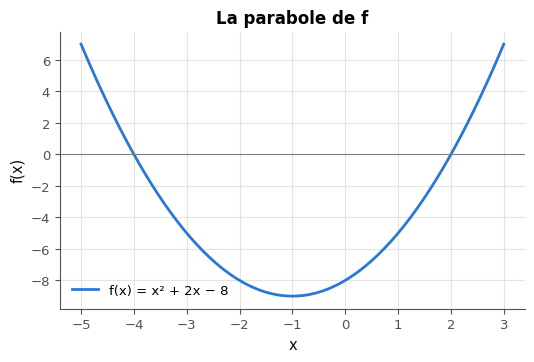

In [13]:
def plot_f():
    """Draw f(x) = x**2 + 2*x - 8 on [-5, 3]: title, axis labels, grid, legend and the line y = 0."""
    xs = np.linspace(-5, 3, 200)
    ys = xs**2 + 2*xs - 8
    fig, ax = plt.subplots(figsize=(6, 3.6))
    ax.plot(xs, ys, label="f(x) = x² + 2x − 8")
    ax.axhline(0, linewidth=0.8, color="gray")
    ax.set_title("La parabole de f")
    ax.set_xlabel("x")
    ax.set_ylabel("f(x)")
    ax.grid(True)
    ax.legend()
    plt.show()


plot_f()

### Ex R0.9 — Ta première fonction : la moyenne (`mean`) 🔨 ★ ⏱️ 25 min
**Objectif :** écrire une fonction de `mymath` d'après son contrat, la tester et écrire ses propres tests.  
**Prérequis :** fiche §7 ; workbookIA 0A §100.3.1 (listes, `len`, `sum`) et §100.5.1 (définir une fonction) · **mymath :** `_example.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`.** Ouvre ta copie `mon_travail/mymath/_example.py` (créée par `python tools/start_chapter.py R0` ; sur Colab, `00_setup/COLAB.md`, « Modifier tes fichiers `.py` »). Lis la docstring de `mean` en entier, remplace la ligne `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie.

- a) Écris `mean(values)` dans `mon_travail/mymath/_example.py` : la somme des valeurs divisée par leur nombre, sous forme de flottant ; une `ValueError` si la suite est vide. Fiche §7, et son piège : teste le vide avec `len(values) == 0`.
- b) Lance les tests de `mean` : la cellule sous « Les tests de `mean` » les exécute ; ils comparent ta fonction à `np.mean`.
- c) Écris **tes propres tests** dans `my_tests` : deux lignes `assert`, l'une sur une liste de deux nombres dont tu connais la moyenne de tête, l'autre sur une liste d'un seul nombre. Dans le notebook, ta fonction s'appelle `mymath._example.mean(...)` (le nom du module, puis celui de la fonction), et non `mean(...)` tout court.

Si tu as déjà fait l'exercice 0A.26 de workbookIA, tu reconnais le mécanisme : ici, c'est ta librairie de maths.

In [14]:
mymath = wbm.load_mymath("ref")
print("mean([2, 4, 9]) =", mymath._example.mean([2, 4, 9]))

mean([2, 4, 9]) = 5.0


In [15]:
wbm.record("R0.9", 5.0, decimals=4,
           mistakes={"divise par le nombre de valeurs, pas par 2": 7.5,
                     "on veut la moyenne, pas la somme : divise par le nombre de valeurs": 15})

WBM_ANSWER {"coarse_any": {"0": ["2cebfa9838e09d4d80aac0cb77dcab60f66ac63f487e4783eef21425b6a251af"]}, "coarser": {"1": ["af4ad7b4f302c53b0db3ca1bb0f8f554091790939e7e2b47d1586f30ff5e655a"], "2": ["b65ba153f6cb1de931e09b82245e886ad4a2d27932402bfbe234d4b60a7494d0"]}, "decimals": 4, "hash": "5f5967bc51b2fb9f139eed227daeb589862251df1f52d15586aca710a522a9b1", "hash_coarse": "31f1eabb53d85e7eb88dd718b43d635fc5545c96d4a02a7dac652cbb780b2a41", "id": "R0.9", "kind": "float", "magnitude": 0, "mistakes": {"8f05cd2a006c816a71c41fb254a8c5ed9b521cfe5c2058a65778880b6f7607f7": "on veut la moyenne, pas la somme : divise par le nombre de valeurs", "c53c2a8063c0037a9d2d7c2e8ef13050f8173a48e85ddc28ef3395b3fc7873a6": "divise par le nombre de valeurs, pas par 2"}, "sign": 1}
📝 Ex R0.9 : réponse enregistrée (float, 4 décimales).


**Les tests de `mean`** (fiche §7 : lis d'abord la ligne qui suit chaque ❌, elle dit ce qui était attendu).

In [16]:
from wbm.nbtools import run_pytest_group

run_pytest_group("tests/test_example_mymath.py", "test_mean", impl="ref")

pytest: 5 réussi(s) en 0,01 s


**Tes propres tests.** Deux lignes `assert` dans `my_tests` (question c).

In [17]:
def my_tests():
    """Two asserts of your own on mymath._example.mean (question c)."""
    assert mymath._example.mean([10, 20]) == 15.0
    assert mymath._example.mean([7]) == 7.0

In [18]:
with wbm.attempt("R0.9 tests"):
    import inspect
    try:
        n_asserts = inspect.getsource(my_tests).count("assert ")
    except (OSError, TypeError):  # the source of the function cannot be read: trust the learner
        n_asserts = 2
    my_tests()
    if n_asserts >= 2:
        print("✅ Ex R0.9 : tes assert passent.")
    else:
        print(f"❌ Ex R0.9 : my_tests contient {n_asserts} ligne(s) assert ; il en faut deux (question c).")

✅ Ex R0.9 : tes assert passent.


💡 Un `assert` qui passe n'affiche rien ; c'est quand il échoue qu'il parle (`AssertionError`).

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu prévoir ce que Python calcule pour `-3 ** 2`, `23 // 4` ou `2 ** 3 ** 2`, et pourquoi `0.1 + 0.2 == 0.3` est faux ?
2. Sais-tu taper une fraction, une expression et un intervalle pour `wbm.check`, et vérifier un développement avec SymPy ?
3. Sais-tu écrire une fonction de `mymath` d'après sa docstring, lancer ses tests et lire un échec ?

**La suite** : le test de positionnement (`python tools/start_chapter.py POS`), puis R1. Dans workbookIA, continue le chapitre 0A (jusqu'à §100.6.2 avant R1).